In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datasets import load_benchmark_dataset
from src.experiment import (
    evaluate_resampling_curve,
    evaluate_naive_bayes_curve,
    evaluate_threshold_curve,
    compute_table3_auc_row,
)
from src.metrics import roc_convex_hull

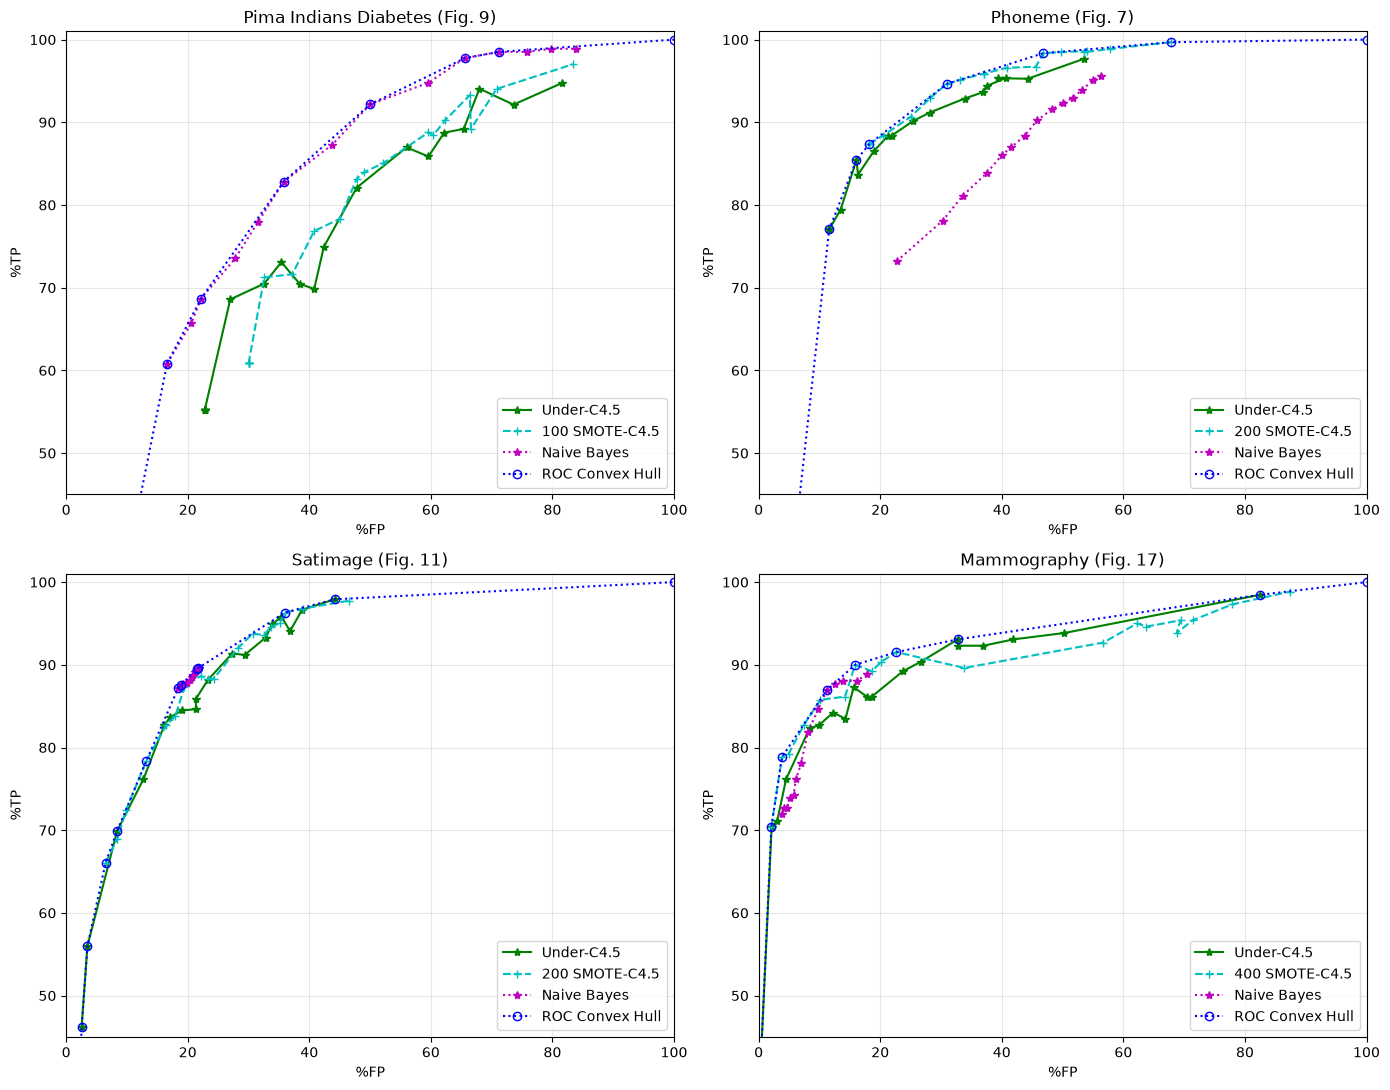

In [2]:
configs = [
    ("pima", 100, "Pima Indians Diabetes (Fig. 9)"),
    ("phoneme", 200, "Phoneme (Fig. 7)"),
    ("satimage", 200, "Satimage (Fig. 11)"),
    ("mammography", 400, "Mammography (Fig. 17)"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (ds_name, best_smote, title) in zip(axes.flat, configs):
    X, y = load_benchmark_dataset(ds_name)
    under_df = evaluate_resampling_curve(X, y, smote_pct=None)
    smote_df = evaluate_resampling_curve(X, y, smote_pct=best_smote)
    nb_df = evaluate_naive_bayes_curve(X, y)

    all_pts = np.vstack([
        under_df[["fp", "tp"]].values,
        smote_df[["fp", "tp"]].values,
        nb_df[["fp", "tp"]].values,
    ])
    hull = roc_convex_hull(all_pts)

    ax.plot(under_df["fp"], under_df["tp"], "g*-", label="Under-C4.5")
    ax.plot(smote_df["fp"], smote_df["tp"], "c+--", label=f"{best_smote} SMOTE-C4.5")
    ax.plot(nb_df["fp"], nb_df["tp"], "m*:", label="Naive Bayes")
    ax.plot(hull[:, 0], hull[:, 1], "bo:", markersize=6, fillstyle="none", label="ROC Convex Hull")

    ax.set_title(title)
    ax.set_xlabel("%FP")
    ax.set_ylabel("%TP")
    ax.set_xlim(0, 100)
    ax.set_ylim(45, 101)
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [3]:
paper_table3 = {
    "Pima": {"Under": 7242, "100 SMOTE": 7307},
    "Phoneme": {"Under": 8622, "100 SMOTE": 8644, "200 SMOTE": 8661},
    "Satimage": {"Under": 8900, "100 SMOTE": 8957, "200 SMOTE": 8979, "300 SMOTE": 8963, "400 SMOTE": 8975, "500 SMOTE": 8960},
    "Mammography": {"Under": 9260, "100 SMOTE": 9250, "200 SMOTE": 9265, "300 SMOTE": 9311, "400 SMOTE": 9330, "500 SMOTE": 9304},
}

reproduced_rows = {}
for ds_label, levels in [
    ("Pima", [100]),
    ("Phoneme", [100, 200]),
    ("Satimage", [100, 200, 300, 400, 500]),
    ("Mammography", [100, 200, 300, 400, 500]),
]:
    X, y = load_benchmark_dataset(ds_label)
    reproduced_rows[ds_label] = compute_table3_auc_row(X, y, smote_levels=levels)

reproduced_df = pd.DataFrame(reproduced_rows).T
paper_df = pd.DataFrame(paper_table3).T

print("=== Reproduced AUCs (x 10,000) ===")
display(reproduced_df)
print("\n=== Original Paper Table 3 AUCs (x 10,000) ===")
display(paper_df)

=== Reproduced AUCs (x 10,000) ===


,Under,100 SMOTE,200 SMOTE,300 SMOTE,400 SMOTE,500 SMOTE
Pima,6589.0,6192.0,NaN,NaN,NaN,NaN
Phoneme,8422.0,8178.0,7969.0,NaN,NaN,NaN
Satimage,9034.0,8885.0,8820.0,8794.0,8741.0,8766.0
Mammography,9188.0,9153.0,9067.0,9109.0,9050.0,9074.0



=== Original Paper Table 3 AUCs (x 10,000) ===


,Under,100 SMOTE,200 SMOTE,300 SMOTE,400 SMOTE,500 SMOTE
Pima,7242.0,7307.0,NaN,NaN,NaN,NaN
Phoneme,8622.0,8644.0,8661.0,NaN,NaN,NaN
Satimage,8900.0,8957.0,8979.0,8963.0,8975.0,8960.0
Mammography,9260.0,9250.0,9265.0,9311.0,9330.0,9304.0
